In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.95" 
import sys
sys.path.append('../')

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline
import jax

import jax.numpy as jnp
import jax.random as jr
import optax
import math

import k3d
from k3d.colormaps import matplotlib_color_maps
import numpy as np
from matplotlib.colors import ListedColormap
from typing import Callable
from functools import partial

from implicitSurfaces.lipschitzImplicit import sdfImplicit
from implicitSurfaces.jnpboundedImplicit import jnpboundedImplicit
from surfaceSampler.sampler import SurfaceSampler
from implicitSurfaces.sdf_primitives import sphere_sdf
from utils.helpers import mesh_2d, mesh_to_vec_2d

In [3]:
def gather_hit_points(output_states) -> jnp.ndarray:
    """
    Gathers hit points from the output state after ray marching is complete.
    """
    N_rays, max_hits = output_states.t_hits.shape
    ray_origins_expanded = output_states.ray_origin[:, None, :]
    ray_directions_expanded = output_states.ray_direction[:, None, :]
    t_expanded = output_states.t_hits[:, :, None]

    all_hit_coordinates = ray_origins_expanded + ray_directions_expanded * t_expanded
    hit_indices = jnp.arange(max_hits)
    valid_hits_mask = hit_indices < output_states.hit_counts[:, None]

    flat_coords = all_hit_coordinates.reshape(-1, output_states.ray_origin.shape[1])
    flat_mask = valid_hits_mask.flatten()
    return flat_coords[flat_mask]

## SDF

### 2d

In [4]:
surface = sdfImplicit(fn=sphere_sdf, dim=2)
params = {'center': jnp.array([0.0, 0.0]), 'radius': jnp.array(1.0)}

In [5]:
surface_sampler = SurfaceSampler(
    surface.ray_step,
    level_set=surface.level_set,
    dim=surface.dim,
    max_step=1000,
    epsilon=1e-5,
    max_hits=20,
    init_trust_region_size=jnp.inf,
)

In [6]:
raybuffer, is_finished = surface_sampler.sample_rays_batched(jr.PRNGKey(0), jnp.array([-2.5, -2.5]), jnp.array([2.5, 2.5]), 100, 100, 1000, dtype=jnp.float32)

In [7]:
bbox_min = jnp.array([-2.0, -2.0])
bbox_max = jnp.array([2.0, 2.0])
num_samples = 100
samples = surface_sampler.sample_surface_points(params, jr.PRNGKey(0), bbox_min, bbox_max, num_samples)

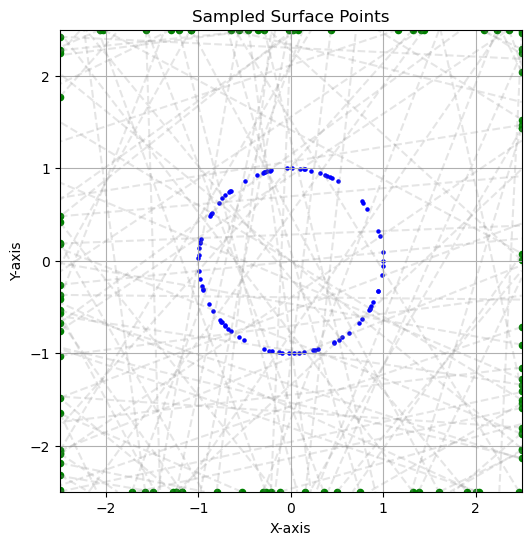

In [8]:
fig = plt.figure(figsize=(6,6))
plt.scatter(raybuffer.ray_origin[:, 0], raybuffer.ray_origin[:, 1], s=20, color='green', label='Ray Origins')
for i in range(raybuffer.ray_origin.shape[0]):
    o = raybuffer.ray_origin[i]
    d = raybuffer.ray_direction[i]
    p_end = o + d * raybuffer.max_ts[i]
    plt.plot([o[0], p_end[0]], [o[1], p_end[1]], color='gray', alpha=0.2, linestyle='--')
plt.scatter(samples[:, 0], samples[:, 1], s=5, color='blue')
plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 2.5)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Sampled Surface Points')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.grid()
plt.show()

### 3d

In [9]:
surface = sdfImplicit(fn=sphere_sdf, dim=3)
params = {'center': jnp.array([0.0, 0.0, 0.0]), 'radius': jnp.array(1.0)}

surface_sampler = SurfaceSampler(
    surface.ray_step,
    level_set=surface.level_set,
    dim=surface.dim,
    max_step=1000,
    epsilon=1e-5,
    max_hits=20,
    init_trust_region_size=jnp.inf,
    debug=True,
    n_compactions=1
)

In [11]:
bbox_min = jnp.array([-2.0, -2.0, -2.0])
bbox_max = jnp.array([2.0, 2.0, 2.0])
num_samples = 10000
active_states, output_states, active_indices = surface_sampler.sample_surface_points(params, jr.PRNGKey(0), bbox_min, bbox_max, num_samples)

In [12]:
raybuffer, is_finished = surface_sampler.sample_rays_batched(jr.PRNGKey(0), bbox_min, bbox_max, 100, 100, 1000, dtype=jnp.float32)

In [13]:
output_states

MultiHitRayOutput(niter=Array([6, 6, 5, ..., 1, 4, 4], dtype=int32), ray_origin=Array([[ 2.        , -1.7758555 , -0.7720008 ],
       [-1.7031643 ,  0.9877483 ,  2.        ],
       [ 0.03800106,  2.        , -0.46413904],
       ...,
       [-0.8430593 , -1.9999999 ,  1.2006494 ],
       [-1.2730958 ,  1.2635462 , -2.        ],
       [ 1.0950751 , -2.        ,  0.4759344 ]], dtype=float32), ray_direction=Array([[-0.4876089 ,  0.864545  , -0.12165308],
       [ 0.6354971 , -0.7006187 , -0.32446408],
       [-0.72182316, -0.691067  ,  0.03738689],
       ...,
       [ 0.27088526,  0.736536  ,  0.619787  ],
       [ 0.2024273 ,  0.14817065,  0.96802306],
       [-0.09420864,  0.5749351 , -0.81275725]], dtype=float32), t_hits=Array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32), hit_coun

In [14]:
surface_points = gather_hit_points(output_states)

In [15]:
is_hit, dirs, origins, hits = jax.vmap(surface_sampler.sampling_ray_bbox_fn, in_axes=(0, None, None, None))(jr.split(jr.PRNGKey(0), 1000), bbox_min, bbox_max, jnp.float32)
origins_plot = origins[is_hit]

In [16]:
plot = k3d.plot()

plot += k3d.points(raybuffer.ray_origin, point_size=0.1, color=0x0000ff, )
plot += k3d.points(origins_plot, point_size=0.1, color=0xff0000)
plot += k3d.points(surface_points, point_size=0.1, color=0x00ff00)

plot.display()

Output()

## Neural Network

In [4]:
from typing import NamedTuple

class Params(NamedTuple):
    w1: jnp.ndarray  # [d_in, d_hidden]
    b1: jnp.ndarray  # [d_hidden]
    w2: jnp.ndarray  # [d_hidden, d_hidden]
    b2: jnp.ndarray  # [d_hidden]
    w3: jnp.ndarray  # [d_hidden, d_hidden]
    b3: jnp.ndarray  # [d_hidden]
    w4: jnp.ndarray  # [d_hidden, d_out]
    b4: jnp.ndarray  # [d_out]


def init_params(d_in, d_hidden, d_out, key):
    w1_key, w2_key, w3_key, w4_key, b1_key, b2_key, b3_key, b4_key = jax.random.split(key, num=8)
    return Params(
        w1=jax.random.uniform(key=w1_key, shape=[d_in, d_hidden], minval=-1/math.sqrt(d_in), maxval=1/math.sqrt(d_in)),
        b1=jax.random.uniform(key=b1_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w2=jax.random.uniform(key=w2_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b2=jax.random.uniform(key=b2_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w3=jax.random.uniform(key=w3_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b3=jax.random.uniform(key=b3_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w4=jax.random.uniform(key=w4_key, shape=[d_hidden, d_out], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b4=jax.random.uniform(key=b4_key, shape=[d_out], minval=-1/math.sqrt(d_out), maxval=1/math.sqrt(d_out)),
    )


def neural_network(params, x):
    x = x @ params.w1 + params.b1
    x = jax.nn.swish(x)
    x = x @ params.w2 + params.b2
    x = jax.nn.swish(x)
    x = x @ params.w3 + params.b3
    x = jax.nn.swish(x)
    x = x @ params.w4 + params.b4
    return x

In [5]:
params = init_params(2, 32, 1, key=jax.random.PRNGKey(1))
LEARNING_RATE = 5e-4
STEPS = 2000
trained_params = init_params(2, 32, 1, key=jax.random.PRNGKey(2))
optim = optax.adam(LEARNING_RATE)

In [6]:
def sdf_circle_jax(X: jnp.ndarray, radius) -> jnp.ndarray:
    return jnp.sqrt(jnp.sum(X**2, axis=-1)) - radius

def train(model, params, optim, ndim, gt_fn, n_steps, bbox, subkey):
    opt_state = optim.init(params)

    def loss_fn(params, X):
        pred_y = jax.vmap(model, in_axes=(None, 0))(params, X)
        true_y = jax.vmap(gt_fn)(X)
        return jnp.mean(jnp.pow((pred_y[:, 0] - true_y), 2))

    @jax.jit
    def step(params, opt_state, X):
        loss, grads = jax.value_and_grad(loss_fn, argnums=0)(params, X)
        update, opt_state = optim.update(grads, opt_state)
        params = optax.apply_updates(params, update)
        return params, opt_state, loss
    
    @jax.jit
    def point_sampler(key):
        key, subkey = jax.random.split(key)
        return jax.random.uniform(key, (10000, ndim), minval=bbox[0], maxval=bbox[1]), subkey

    for iter in range(0, n_steps):
        XY, subkey = point_sampler(subkey)
        params, opt_state, loss = step(params, opt_state, XY)
        if iter % 100 == 0:
            print(f"Iteration {iter}, loss: {loss}")
    return params

In [7]:
trained_params = train(
    model=neural_network,
    params=params,
    optim=optim,
    ndim=2,
    gt_fn=partial(sdf_circle_jax, radius=1.0),
    n_steps=STEPS,
    bbox=(-1, 1),
    subkey=jax.random.PRNGKey(0)
)

Iteration 0, loss: 0.685141921043396
Iteration 100, loss: 0.11117833852767944
Iteration 200, loss: 0.06821010261774063
Iteration 300, loss: 0.020124031230807304
Iteration 400, loss: 0.003082415321841836
Iteration 500, loss: 0.003066430799663067
Iteration 600, loss: 0.0029219365678727627
Iteration 700, loss: 0.0027208265382796526
Iteration 800, loss: 0.0025859989691525698
Iteration 900, loss: 0.002428139792755246
Iteration 1000, loss: 0.002310376614332199
Iteration 1100, loss: 0.002308696275576949
Iteration 1200, loss: 0.002115077804774046
Iteration 1300, loss: 0.0019220272079110146
Iteration 1400, loss: 0.0018832448404282331
Iteration 1500, loss: 0.0016506133833900094
Iteration 1600, loss: 0.00159799016546458
Iteration 1700, loss: 0.0014794189482927322
Iteration 1800, loss: 0.0014011936727911234
Iteration 1900, loss: 0.0011811990989372134


In [8]:
res = 100

mesh_x, mesh_y = mesh_2d(res, ((-2.0, 2.0), (-2.0, 2.0)))

X_jnp = mesh_to_vec_2d(mesh_x, mesh_y)
Z_nn = jax.vmap(neural_network, in_axes=(None, 0))(trained_params, X_jnp)

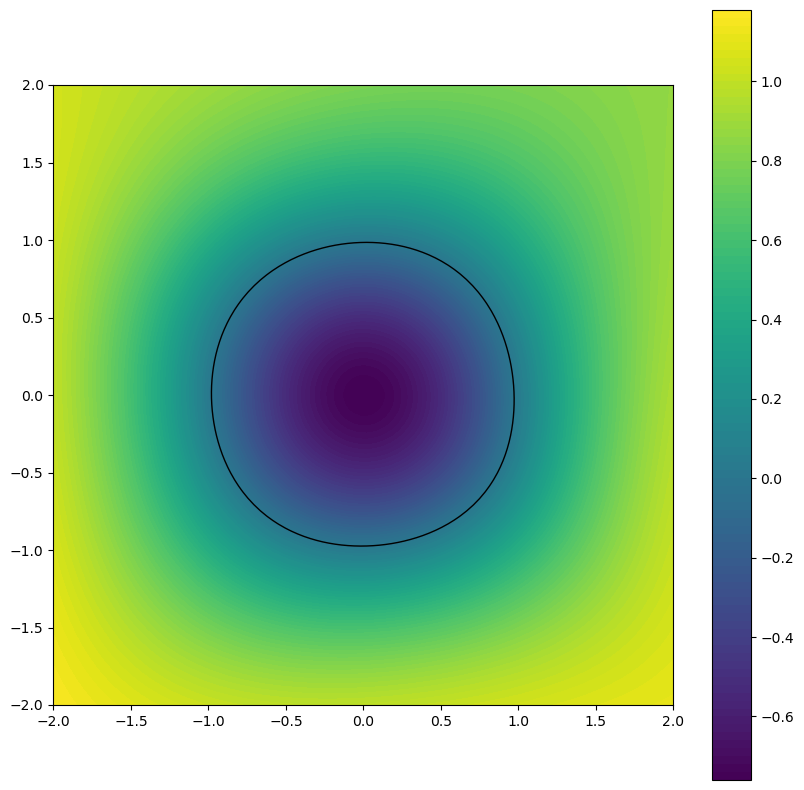

In [9]:
fig = plt.figure(figsize=(10, 10))

ax = fig.add_subplot(111)
ax.set_aspect('equal')
"""
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_xlim(-1.1, -0.9)
ax.set_ylim(-0.1, 0.1)
"""

contourf = ax.contourf(mesh_x, mesh_y, Z_nn.reshape(mesh_x.shape), levels=100, cmap='viridis')
ax.contour(mesh_x, mesh_y, Z_nn.reshape(mesh_x.shape), levels=0, colors='black', linewidths=1)
fig.colorbar(contourf, ax=ax, orientation='vertical')

In [10]:
jnp_surface = jnpboundedImplicit(
    fn=lambda x: neural_network(trained_params, x),
    dim=2,
    autobounds_max_degree=2,
    level_set=0.0,
)

In [11]:
jnp_surface_sampler = SurfaceSampler(
    jnp_surface.ray_step,
    level_set=jnp_surface.level_set,
    dim=jnp_surface.dim,
    max_step=1000,
    epsilon=1e-5,
    max_hits=20,
    init_trust_region_size=0.5,
    n_compactions=2,
    debug=True,
)


In [12]:
jnp_surface.ray_step(
    params=None,
    ray_origin=jnp.array([0.0, 0.0]),
    ray_direction=jnp.array([1.0, 0.0]),
    trust_region_size=jnp.array(0.5),
)

(Array([-0.7588449], dtype=float32),
 Array([0.25], dtype=float32),
 Array([ True], dtype=bool))

In [13]:
active_states, output_states, active_indices = jnp_surface_sampler.sample_surface_points(
    params=None,
    key=jax.random.PRNGKey(42),
    bbox_min=jnp.array([-2.0, -2.0]),
    bbox_max=jnp.array([2.0, 2.0]),
    num_rays=1000,
)

In [14]:
surface_samples = gather_hit_points(output_states)

In [15]:
output_states.hit_counts

Array([2, 2, 0, 0, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 2, 0,
       2, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 0,
       0, 2, 0, 2, 0, 0, 0, 2, 0, 2, 2, 0, 2, 2, 2, 2, 2, 0, 2, 0, 2, 0,
       0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 2, 2,
       0, 0, 2, 0, 0, 0, 2, 2, 0, 2, 2, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0, 2,
       0, 2, 0, 0, 0, 0, 2, 0, 0, 0, 2, 2, 0, 2, 0, 2, 0, 0, 2, 2, 2, 0,
       2, 0, 0, 2, 0, 2, 2, 2, 0, 0, 2, 2, 0, 2, 2, 0, 2, 0, 0, 0, 0, 0,
       0, 2, 0, 2, 0, 0, 0, 0, 0, 2, 0, 2, 2, 0, 0, 0, 0, 2, 0, 0, 0, 0,
       2, 2, 0, 2, 2, 2, 2, 2, 0, 0, 2, 0, 0, 0, 0, 2, 2, 0, 0, 2, 0, 0,
       0, 2, 0, 2, 2, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 0, 2,
       0, 0, 2, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 0, 2, 0, 0, 2, 0, 0, 0, 0,
       0, 0, 2, 2, 0, 2, 0, 2, 0, 0, 0, 0, 2, 0, 2, 0, 0, 0, 0, 2, 0, 0,
       0, 2, 2, 2, 0, 2, 2, 0, 2, 0, 0, 2, 2, 0, 2, 0, 0, 2, 2, 0, 0, 0,
       2, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2,

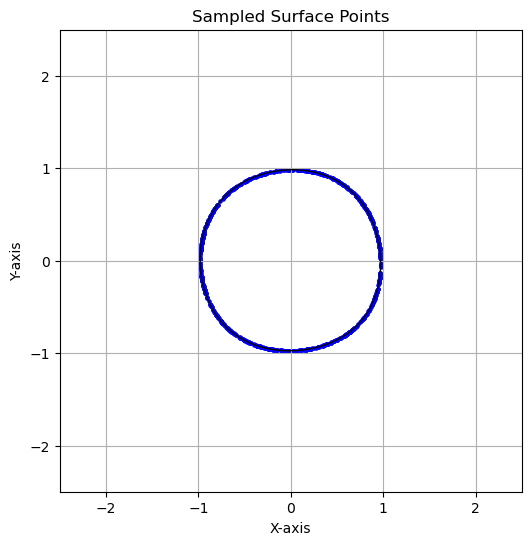

In [17]:
fig = plt.figure(figsize=(6,6))
plt.contour(mesh_x, mesh_y, Z_nn.reshape(mesh_x.shape), levels=0, colors='black', linewidths=1)

plt.scatter(surface_samples[:, 0], surface_samples[:, 1], s=5, color='blue')
plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 2.5)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Sampled Surface Points')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.grid()
plt.show()

### 3d

In [18]:
@partial(jax.jit, static_argnames=['radius'])
def sdf_sphere_jax(x: jnp.ndarray, radius: float) -> jnp.ndarray:
    return jnp.linalg.norm(x, axis=-1) - radius


@partial(jax.jit, static_argnames=['r', 'R'])
def sdf_torus_jax(x: jnp.ndarray, r: float, R: float) -> jnp.ndarray:
    q = jnp.sqrt(jnp.pow(x[0], 2) + jnp.pow(x[2], 2)) - R
    return jnp.sqrt(jnp.pow(q, 2) + jnp.pow(x[1], 2)) - r

def twistOperation(fn: Callable, k: float) -> Callable:
    @jax.jit
    def twist(x: jnp.ndarray):
        c = jnp.cos(k * x[1])
        s = jnp.sin(k * x[1])
        m = jnp.array([[c, 0., -s], [s, 0., c], [0., 1., 0.]])
        return fn(jnp.matmul(m, x))
    return twist

In [19]:
LEARNING_RATE = 1e-2
STEPS = 5000
RADIUS = 0.5
RADIUS_INNER = 0.2
NDIM = 3
HIDDEN_DIM = 128

params = init_params(NDIM, HIDDEN_DIM, 1, key=jax.random.PRNGKey(1))
trained_params = init_params(NDIM, HIDDEN_DIM, 1, key=jax.random.PRNGKey(2))
optim = optax.adam(LEARNING_RATE)

trained_params = train(
    model=neural_network,
    params=params,
    optim=optim,
    ndim=NDIM,
    gt_fn=twistOperation(partial(sdf_torus_jax, r=RADIUS_INNER, R=RADIUS), k=5.),
    n_steps=STEPS,
    bbox=(-1, 1),
    subkey=jax.random.PRNGKey(0)
)

Iteration 0, loss: 0.08659186959266663
Iteration 100, loss: 0.01814108155667782
Iteration 200, loss: 0.017566347494721413
Iteration 300, loss: 0.017184505239129066
Iteration 400, loss: 0.01708005554974079
Iteration 500, loss: 0.016074076294898987
Iteration 600, loss: 0.006853591650724411
Iteration 700, loss: 0.003077957546338439
Iteration 800, loss: 0.0023844444658607244
Iteration 900, loss: 0.0010479377815499902
Iteration 1000, loss: 0.0009184993687085807
Iteration 1100, loss: 0.0007361778989434242
Iteration 1200, loss: 0.0006062471074983478
Iteration 1300, loss: 0.0005826386041007936
Iteration 1400, loss: 0.00046681868843734264
Iteration 1500, loss: 0.0004034062149003148
Iteration 1600, loss: 0.0003708061994984746
Iteration 1700, loss: 0.00032552520860917866
Iteration 1800, loss: 0.0004984120023436844
Iteration 1900, loss: 0.0004093308234587312
Iteration 2000, loss: 0.01355039980262518
Iteration 2100, loss: 0.0015772241167724133
Iteration 2200, loss: 0.0007510478608310223
Iteration 2

In [20]:
x0 = 0.0
offset = 1.0
level_set = 0.0


x_vals = jnp.linspace(x0 - offset, x0 + offset, 128)
y_vals = jnp.linspace(x0 - offset, x0 + offset, 128)
z_vals = jnp.linspace(x0 - offset, x0 + offset, 128)
X, Y, Z = jnp.meshgrid(x_vals, y_vals, z_vals)

grid_points = jnp.stack([X.ravel(), Y.ravel(), Z.ravel()], axis=-1)
fn_vals = jax.vmap(neural_network, in_axes=(None, 0))(trained_params, grid_points).reshape(X.shape)
#fn_vals = jax.vmap(twistOperation(partial(sdf_torus_jax, r=RADIUS_INNER, R=RADIUS_OUTER), k=5.))(grid_points).reshape(X.shape)
fn_vals_normalized = (fn_vals - jnp.min(fn_vals)) / (jnp.max(fn_vals) - jnp.min(fn_vals))
fn_vals_normalized_np = fn_vals_normalized.astype(np.float64)
level_set_normalized = (level_set - jnp.min(fn_vals)) / (jnp.max(fn_vals) - jnp.min(fn_vals))

/system/apps/userenv/volkmann/jax_env/lib/python3.14/site-packages/jax/_src/numpy/array_methods.py:125: UserWarning: Explicitly requested dtype <class 'numpy.float64'> requested in astype is not available, and will be truncated to dtype float32. To enable more dtypes, set the jax_enable_x64 configuration option or the JAX_ENABLE_X64 shell environment variable. See https://github.com/jax-ml/jax#current-gotchas for more.
  return lax_numpy.astype(self, dtype, copy=copy, device=device)


In [21]:
plot = k3d.plot()

iso_surf = k3d.marching_cubes(
    fn_vals_normalized_np, 
    level=level_set_normalized.astype(np.float32).item(),
    xmin=x0 - offset, xmax=x0 + offset,
    ymin=x0 - offset, ymax=x0 + offset,
    zmin=x0 - offset, zmax=x0 + offset,
    color=0x00ff00, 
    opacity=1.)
plot += iso_surf

plot.display()

Output()

In [28]:
jnp_surface = jnpboundedImplicit(
    fn=lambda x: neural_network(trained_params, x),
    dim=3,
    autobounds_max_degree=2,
    level_set=0.0,
)

jnp_surface_sampler = SurfaceSampler(
    jnp_surface.ray_step,
    level_set=jnp_surface.level_set,
    dim=jnp_surface.dim,
    max_step=100,
    epsilon=1e-5,
    max_hits=20,
    init_trust_region_size=0.5,
    n_compactions=11,
    debug=True,
)

In [38]:
surface_points_accumulated = jnp.empty((0, 3), dtype=jnp.float32)
for i in range(10):
    active_states, output_states, active_indices = jnp_surface_sampler.sample_surface_points(
        params=None,
        key=jax.random.PRNGKey(i),
        bbox_min=jnp.array([-2.0, -2.0, -2.0]),
        bbox_max=jnp.array([2.0, 2.0, 2.0]),
        num_rays=10000,
    )
    new_points = gather_hit_points(output_states)
    surface_points_accumulated = jnp.concatenate([surface_points_accumulated, new_points], axis=0)
    print(f"Iteration {i}, accumulated points: {surface_points_accumulated.shape[0]}")

Iteration 0, accumulated points: 408
Iteration 1, accumulated points: 802
Iteration 2, accumulated points: 1225
Iteration 3, accumulated points: 1636
Iteration 4, accumulated points: 2079
Iteration 5, accumulated points: 2485
Iteration 6, accumulated points: 2935
Iteration 7, accumulated points: 3374
Iteration 8, accumulated points: 3715
Iteration 9, accumulated points: 4109


In [31]:
active_states, output_states, active_indices = jnp_surface_sampler.sample_surface_points(
    params=None,
    key=jax.random.PRNGKey(42),
    bbox_min=jnp.array([-2.0, -2.0, -2.0]),
    bbox_max=jnp.array([2.0, 2.0, 2.0]),
    num_rays=10000,
)

surface_points = gather_hit_points(output_states)

In [32]:
max_iter_state = jnp.argmax(output_states.niter)
output_states.niter[max_iter_state], output_states.hit_counts[max_iter_state], output_states.t_hits[max_iter_state, :output_states.hit_counts[max_iter_state]], output_states.ray_origin[max_iter_state], output_states.ray_direction[max_iter_state]

(Array(100, dtype=int32),
 Array(0, dtype=int32),
 Array([], shape=(0,), dtype=float32),
 Array([-0.18652415,  2.        , -1.3762268 ], dtype=float32),
 Array([-0.1797233, -0.5536117,  0.8131504], dtype=float32))

(array([3582., 1571.,  979.,  775.,  524.,  446.,  327.,  256.,  199.,
        1341.]),
 array([  1. ,  10.9,  20.8,  30.7,  40.6,  50.5,  60.4,  70.3,  80.2,
         90.1, 100. ]),
 <BarContainer object of 10 artists>)

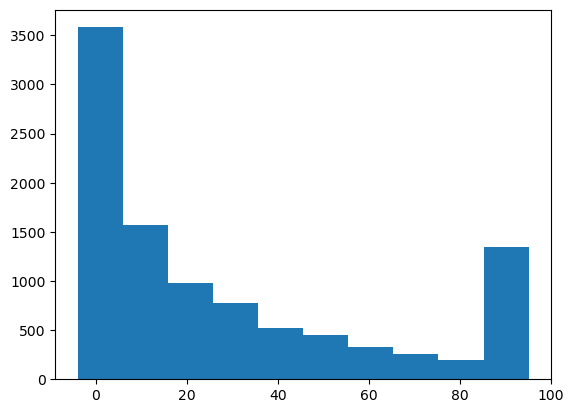

In [33]:
plt.hist(output_states.niter, align='left')

In [34]:
plot = k3d.plot()

plot += k3d.points(surface_points, point_size=0.05, color=0x00ff00)

plot.display()

Output()

Generating GIF, please wait...


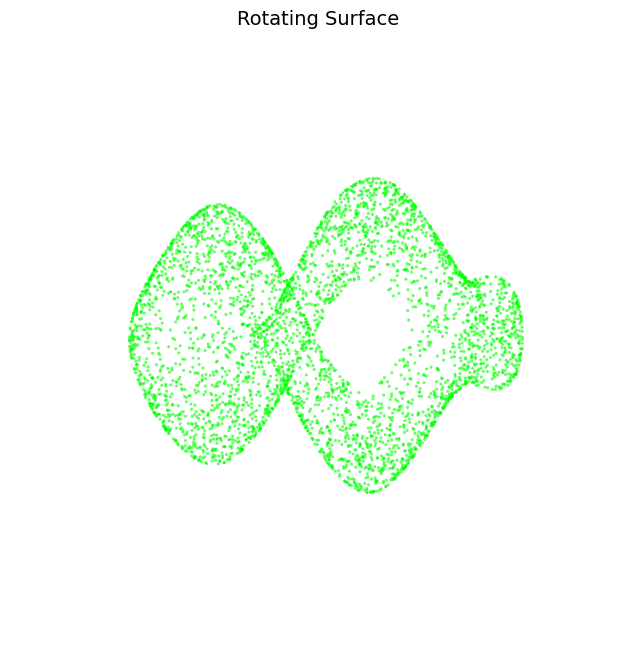

In [39]:
import matplotlib.animation as animation

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the points
# Adjust 's' (size), 'alpha' (transparency), and 'c' (color) as needed
scatter = ax.scatter(surface_points_accumulated[:, 0], 
                     surface_points_accumulated[:, 1], 
                     surface_points_accumulated[:, 2], 
                     s=5, c='#00ff00', alpha=0.6, edgecolors='none')

# Clean up the visual space
ax.set_axis_off()          # Hide axes, grid, and background
ax.set_title("Rotating Surface", fontsize=14)

# Set equal aspect ratio to prevent stretching
max_range = np.array([surface_points_accumulated[:, 0].max()-surface_points_accumulated[:, 0].min(), 
                      surface_points_accumulated[:, 1].max()-surface_points_accumulated[:, 1].min(), 
                      surface_points_accumulated[:, 2].max()-surface_points_accumulated[:, 2].min()]).max() / 2.0
mid_x = (surface_points_accumulated[:, 0].max()+surface_points_accumulated[:, 0].min()) * 0.5
mid_y = (surface_points_accumulated[:, 1].max()+surface_points_accumulated[:, 1].min()) * 0.5
mid_z = (surface_points_accumulated[:, 2].max()+surface_points_accumulated[:, 2].min()) * 0.5

ax.set_xlim(mid_x - max_range, mid_x + max_range)
ax.set_ylim(mid_y - max_range, mid_y + max_range)
ax.set_zlim(mid_z - max_range, mid_z + max_range)

# ==========================================
# 3. Create the Animation
# ==========================================
def update(frame):
    """
    Update function for the animation. 
    Changes the viewing angle for each frame.
    """
    # ax.view_init(elevation, azimuth)
    # We keep elevation constant at 30, and rotate azimuth by the frame count
    ax.view_init(elev=30, azim=frame)
    return scatter,

# Create an animation that rotates a full 360 degrees
# frames=360 means it will call update() 360 times, passing 0 to 359
# interval=50 is the delay between frames in milliseconds (20 FPS)
anim = animation.FuncAnimation(fig, update, frames=np.arange(0, 360, 2), interval=50, blit=False)

# ==========================================
# 4. Save the GIF
# ==========================================
print("Generating GIF, please wait...")
# Using the 'pillow' writer which is built into matplotlib and doesn't require extra installs
anim.save('rotating_surface.gif', writer='pillow', fps=20)

Cubic Coefficients:
a30: -1.25, a03: 4.51, a21: 2.32, a12: 0.99

Actual Maximum (Spectral Norm): 4.559
Calculated Bound (Frobenius Norm): 4.900
Efficiency Ratio (Spectral / Frobenius): 0.93


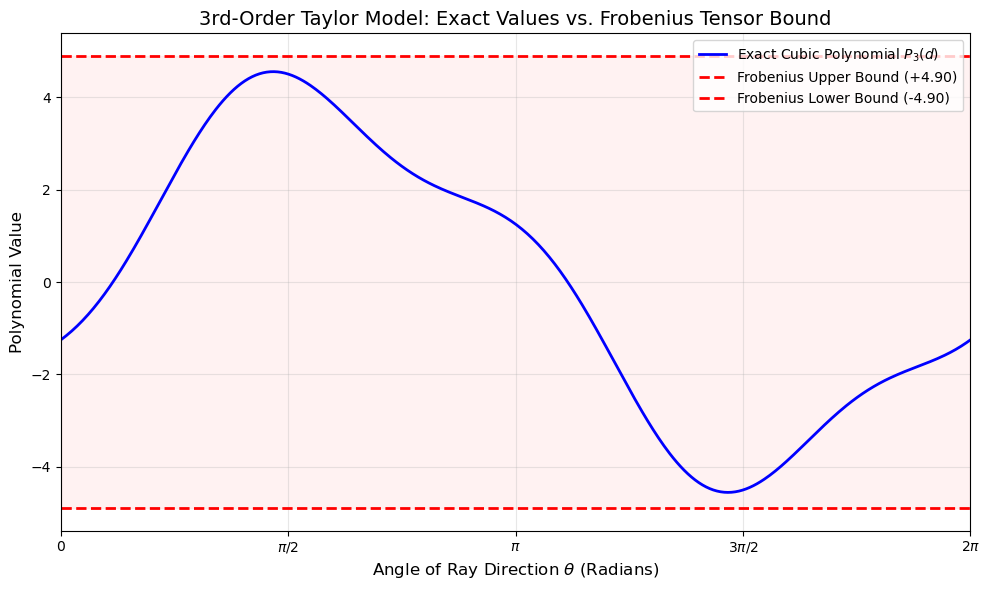

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def visualize_frobenius_bound():
    # 1. Generate random polynomial coefficients for a 2D Taylor model
    np.random.seed(42)
    a30 = np.random.uniform(-5, 5)
    a03 = np.random.uniform(-5, 5)
    a21 = np.random.uniform(-5, 5)
    a12 = np.random.uniform(-5, 5)

    print(f"Cubic Coefficients:")
    print(f"a30: {a30:.2f}, a03: {a03:.2f}, a21: {a21:.2f}, a12: {a12:.2f}\n")

    # 2. Evaluate the exact Cubic Polynomial over a 2D unit circle
    theta = np.linspace(0, 2 * np.pi, 500)
    dx = np.cos(theta)
    dy = np.sin(theta)

    # P3(d) = a30*x^3 + a03*y^3 + a21*x^2*y + a12*x*y^2
    exact_polynomial = a30 * dx**3 + a03 * dy**3 + a21 * (dx**2) * dy + a12 * dx * (dy**2)

    # 3. Compute the Frobenius Norm Bound (K3)
    # For a symmetric 2D 3rd-order tensor, the permutations give us the 1/3 scalar for mixed terms
    K3 = np.sqrt(a30**2 + a03**2 + (1.0/3.0) * a21**2 + (1.0/3.0) * a12**2)
    
    # The spectral norm (actual maximum)
    spectral_norm = np.max(np.abs(exact_polynomial))
    
    print(f"Actual Maximum (Spectral Norm): {spectral_norm:.3f}")
    print(f"Calculated Bound (Frobenius Norm): {K3:.3f}")
    print(f"Efficiency Ratio (Spectral / Frobenius): {spectral_norm / K3:.2f}")

    # 4. Plotting
    plt.figure(figsize=(10, 6))
    
    # Plot the exact variation of the cubic terms over all possible directions
    plt.plot(theta, exact_polynomial, label='Exact Cubic Polynomial $P_3(d)$', color='blue', linewidth=2)
    
    # Plot the Frobenius norm bounds
    plt.axhline(K3, color='red', linestyle='--', linewidth=2, label=f'Frobenius Upper Bound (+{K3:.2f})')
    plt.axhline(-K3, color='red', linestyle='--', linewidth=2, label=f'Frobenius Lower Bound (-{K3:.2f})')
    
    # Fill the safe region
    plt.fill_between(theta, -K3, K3, color='red', alpha=0.05)

    plt.title('3rd-Order Taylor Model: Exact Values vs. Frobenius Tensor Bound', fontsize=14)
    plt.xlabel('Angle of Ray Direction $\\theta$ (Radians)', fontsize=12)
    plt.ylabel('Polynomial Value', fontsize=12)
    plt.xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi], ['0', '$\\pi/2$', '$\\pi$', '$3\\pi/2$', '$2\\pi$'])
    plt.xlim(0, 2*np.pi)
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper right')
    
    plt.tight_layout()
    plt.show()

visualize_frobenius_bound()